In [110]:
from tqdm import tqdm, trange
from skimage import io, color
from scipy.ndimage import gaussian_filter, gaussian_laplace
import jax.numpy as np
import numpy as onp 
import os
from glob import glob
from sklearn.cluster import KMeans


ModuleNotFoundError: No module named 'jax'

In [2]:
DATA_DIR = '../../test_data/MSRC_v2/Images/'
image_files = np.sort(glob(DATA_DIR + '*.bmp'))

In [109]:
def get_image_paths(data_dir):
    return np.sort(glob(data_dir + '*.bmp'))

def show_image(image_files, image_id):
    io.imshow(image_files[image_id])
    return

def load_image(image_files, image_id):
    arr = io.imread(image_files[image_id])
    return arr

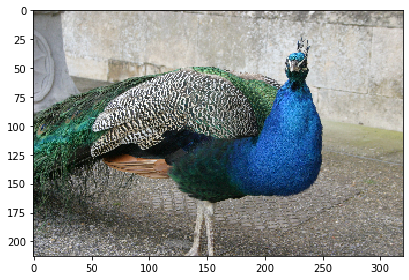

In [4]:
show_image(image_files, 72)

In [83]:
def make_visual_words(arr, word_dims=(3,3)):
    '''
    Breaks image into visual words. 
    
    Parameters
    ----------
        arr     :     array-like
            the image RGB array
        word_dims     :     tuple of ints
            desired (x, y) dimensions of the visual word
    
    Returns
    -------
        visual_words     :     array-like
            visual words for arr
        coords     :     array-like
            array of (x,y) tuples as coordinates of 
            visual words
    '''
    
    visual_words = []
    coords = []
    
    # Pointers
    left_idx = 0  # pointer for the left side of visual word
    right_idx = word_dims[1] # pointer for the right side of visual word
    top_idx = 0 # pointer for the top side of visual word
    bot_idx = word_dims[0] # pointer for the bottom side of visual word (assuming 0 is at top)
    
    # Image boundaries
    max_right_idx = arr.shape[0] 
    max_bot_idx = arr.shape[1]
    #print(max_right_idx, max_bot_idx)
    
    # Set step size
    horz_inc = word_dims[1]
    vert_inc = word_dims[0]
    
    # this will allow for overlapping words, but i don't think we want this.
    #horz_inc = 1
    #vert_inc = 1
    
    # Traverse the image 
    while bot_idx < max_bot_idx:
        while right_idx < max_right_idx:
            # Extract visual word
            new_word = arr[left_idx:right_idx, top_idx:bot_idx, :]
            
            # Store word and associated (x,y)
            visual_words.append(new_word)
            x = np.floor(right_idx - (word_dims[1]/2))
            y = np.floor(bot_idx - (word_dims[0]/2))
            coords.append((x,y))
            
            # Increment horizontal pointers
            right_idx += horz_inc
            left_idx += horz_inc
        
        # Increment vertical pointers
        bot_idx += vert_inc
        top_idx += vert_inc
        
        # Reset horizontal pointers
        left_idx = 0  # pointer for the left side of visual word
        right_idx = word_dims[1] # pointer for the right side of visual word
    
    return np.array(visual_words), coords

def featurize_visual_word(visual_word, total_features = 17):
    '''
    Applies the series of convolutional operations
    specified in "Object Categorization by Learned 
    Universal Visual Dictionary": 3 Gaussians, 4
    Laplacian of Guassians, 4 first order derivatives
    of Gaussians. 
    
    Parameters
    ----------
        visual_word     :     array-like
            the extracted visual word from an image
        total_feautures     :     int
            the number of features in the featurized
            word, according to the paper this is 17. 
    
    Returns
    -------
        featurized_word      :     array-like
            the visual word with additional feature
            channels
    '''
    # Make new word (empty)
    featurized_word_shape = (visual_word.shape[0], visual_word.shape[1], total_features)
    featurized_word = np.zeros(featurized_word_shape)
    
    # Convert to the Lab space whatever this is
    visual_word = color.rgb2lab(visual_word)
    
    # Apply the filters to fill the channels. 
    
    # three Gaussian kernels applied to each L,a,b channel 
    
    idx_pairs = [(0,0,1), (1, 1, 1), (2,2,1), (3,0,2), (4, 1, 2), (5,2,2),
                 (6,0,4), (7, 1, 4), (8,2,4)]
            
    for idx in idx_pairs:
        featurized_word[:, :, idx[0]] = gaussian_filter(visual_word[:, :, idx[1]],sigma = idx[2])
        
    # Four LoGs applied to L channel only
    i = 9
    for sigma in [1, 2, 4, 8]:
        featurized_word[:, :, i] = gaussian_laplace(visual_word[:, :, 0], sigma)
        i += 1
    
    #four derivatives of Gaussians were divided into the two x− and y−aligned sets, each with two different
    #values of σ (σ = 2, 4). Applied to the L channel only.
    
    featurized_word[:, :, 13] = gaussian_filter(visual_word[:, :, 0], sigma = 2, order = [0,1])
    featurized_word[:, :, 14] = gaussian_filter(visual_word[:, :, 0], sigma = 2, order = [1,0])
    featurized_word[:, :, 15] = gaussian_filter(visual_word[:, :, 0], sigma = 4, order = [0,1])
    featurized_word[:, :, 16] = gaussian_filter(visual_word[:, :, 0], sigma = 4, order = [1,0])
    
    return featurized_word

def get_image_shape(img):
    '''
    Returns the shape of the image to be used
    as bounds of document centers. 
    
    Parameters
    ----------
        img     :      array-like
            the array representation of image
    
    Returns
    -------
        shape     :      tuple
            shape of image
    '''
    
    return img.shape[:2]

In [111]:
def assemble_visual_word_data(image_files, word_dims = (3,3)):
    '''
    Extracts the visual words for all image files, featurizes
    them, and constructs the c tuples to track word coordinate
    and associated image.
    
    Parameters
    ----------
        image_files   :   array-like
            paths to the image files 
        word_dims     :     tuple of ints
            desired (x, y) dimensions of the visual word
            
    Returns
    -------
        c     :     array-like
            the (img_id, x, y) tuples of the visual words, 
            denoted in SLDA paper by c
        all_words     :     array-like
            all visual words in the dataset
        
        all_shapes     :     array-like
            array of shape tuples
    '''
    
    c = [] #this contains the tuples of img_id, x, y
    all_imgs = [load_image(image_files, i) for i in range(0, len(image_files))]
    all_words = []
    
    # Get image shapes
    all_shapes = [get_image_shape(img) for img in all_imgs]
    
    # Make visual words
    img_id = 0
    for i in trange(0, len(all_imgs)):
        img = all_imgs[i]
        visual_words, coords = make_visual_words(img, word_dims)
        #print('Featurizing image %s' % img_id)
        for j in range(0, len(visual_words)):
            all_words.append(featurize_visual_word(visual_words[j]))
            x = coords[j][0]
            y = coords[j][1]
            c.append((img_id, x, y))
        
        img_id += 1
    
    return np.array(c), np.array(all_words), np.array(all_shapes)
    
def cluster_descriptors(all_words, vocab_size):
    
    '''
    Creates a summarized feature for each visual word
    and clusters it with KMeans. 
    
    Parameters
    ----------
        all_words     :     array
            the visual words to cluster
        vocab_size      :     int
            the number of words in the vocabulary
    
    Returns
    -------
        kmeans     :      sklearn.cluster.KMeans object
            the clustering object
        assignments     :     array
            assignments of each visual word to cluster id
    '''
    
    # Reshape so the visual word is a 1x9 instead of 3x3, average 
    # features over that axis for each word (so now each is word is 
    # 1x17 features)
    averaged_features = np.mean(all_words.reshape((all_words.shape[0], 
                                all_words.shape[1] * all_words.shape[2], 
                                all_words.shape[3])), axis=1)
    
    
    kmeans = KMeans(n_clusters = vocab_size, random_state = 42)
    assignments = kmeans.fit_predict(averaged_features)
    
    return assignments, kmeans

In [112]:
c, all_words, all_shapes = assemble_visual_word_data(image_files)

100%|██████████| 591/591 [3:00:22<00:00, 18.31s/it]  


In [95]:
arr = io.imread(image_files[0])

In [96]:
all_words.shape

(37100, 3, 3, 17)

In [99]:
np.mean(all_words.reshape((all_words.shape[0], all_words.shape[1] * all_words.shape[2], all_words.shape[3])), axis=1).shape

(37100, 17)

In [31]:
for vw in visual_words:
    if vw.shape != (3,3,3):
        print(vw.shape)

In [34]:
len(visual_words)

66570

In [37]:
np.array(visual_words).shape

(66570, 3, 3, 3)

In [51]:
img = io.imread(image_files[0])

In [53]:
img.shape[:2]

(213, 320)

In [106]:
averaged_features = np.mean(all_words.reshape((all_words.shape[0], 
                                all_words.shape[1] * all_words.shape[2], 
                                all_words.shape[3])), axis=1)
    
    
kmeans = KMeans(n_clusters = 10, random_state = 42)

In [108]:
kmeans.fit_predict(averaged_features)

array([6, 6, 6, ..., 1, 1, 1], dtype=int32)

In [113]:
all_words.shape

(4484436, 3, 3, 17)

In [114]:
np.save('../../test_data/MSRC_v2/featurized_msrc.npy', all_words)
np.save('../../test_data/MSRC_v2/all_shapes_msrc.npy', all_shapes)
np.save('../../test_data/MSRC_v2/c_msrc.npy', c)

NameError: name 'torch' is not defined